# 🛵 Singapore Food Delivery Analyzer (GPU-Accelerated)

> ⚠️ **Mock data:** all orders in this notebook are randomly generated for learning and demo purposes. They are not real customers, deliveries or company data.
**Course:** Fundamentals of Accelerated Data Science (NVIDIA DLI)

**Scenario:** A food delivery start-up (imaginary) has **5 million mock orders** across Singapore. They want to know:
1. Which areas and hours have the most late deliveries?
2. Where should they open **6 cloud kitchens**?
3. Where are the **hotspots** of late orders?
4. Which kitchen is nearest to each customer?
5. Can we **predict** if an order will be late?

**What this shows I understand (mapped to the course):**

| Part | Course concept |
| --- | --- |
| 1. Generate data | Working with tens of millions of rows |
| 2. pandas vs cuDF | GPU DataFrames, speed-up |
| 3. Memory | dtypes, `astype`, categorical |
| 4. Analysis | Boolean masks, groupby, mean-of-0/1 rate trick, pivot table |
| 5. Charts | Bar chart, Datashader-style density map |
| 6. ETL | CSV vs Parquet |
| 7. CuPy | GPU array maths for coordinate conversion |
| 8-11. cuML | K-Means, DBSCAN, KNN, XGBoost + AUC |
| 12. cuGraph (or NetworkX) | Graph, shortest path, PageRank |

**How to run:** Google Colab -> Runtime -> Change runtime type -> **T4 GPU** -> Run all. About 5-10 minutes.

*The data is **mock data** (randomly generated in Part 1), so the notebook works offline with no downloads.*

**Live app:** the interactive Streamlit version of this project runs the same analysis on a CPU. This notebook shows the GPU speed.

In [1]:
# Setup: Colab GPU runtimes already include RAPIDS cuDF and cuML. Nothing to install.
# (Do NOT pip install cudf/cuml here: it clashes with Colab's built-in versions.)
import cudf, cuml

# cuGraph is optional: used in Part 12 if available, otherwise NetworkX (CPU) is used instead.
try:
    import cugraph
    HAS_CUGRAPH = True
except ImportError:
    HAS_CUGRAPH = False

import pandas as pd, numpy as np, cupy as cp, time, matplotlib.pyplot as plt
!nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv
print("cuDF", cudf.__version__, "| cuML", cuml.__version__, "| cuGraph:", "yes" if HAS_CUGRAPH else "not installed (Part 12 will use NetworkX)")

def timer(label, fn):
    start = time.time(); result = fn(); secs = time.time() - start
    print(f"{label:35s} {secs:7.3f} s")
    return result, secs

name, memory.used [MiB], memory.total [MiB]
Tesla T4, 0 MiB, 15360 MiB
cuDF 26.06.00 | cuML 26.06.00 | cuGraph: not installed (Part 12 will use NetworkX)


## Part 1: Generate 5 million mock orders
⚠️ This is **mock data**, not real orders.
Customers cluster around 8 town centres. Late deliveries are more likely when it rains, at peak hours, and for long distances.

In [2]:
rng = np.random.default_rng(42)
N = 5_000_000

towns = {  # name: (lat, long)
    "CBD": (1.283, 103.851), "Jurong": (1.333, 103.742), "Tampines": (1.354, 103.945),
    "Woodlands": (1.436, 103.786), "Bishan": (1.351, 103.848), "Punggol": (1.405, 103.902),
    "Clementi": (1.315, 103.765), "Bedok": (1.324, 103.930),
}
names = np.array(list(towns))
centre = rng.integers(0, len(towns), N)
lat  = np.array([towns[n][0] for n in names])[centre] + rng.normal(0, 0.012, N)
long = np.array([towns[n][1] for n in names])[centre] + rng.normal(0, 0.012, N)

hour  = rng.choice(np.arange(24), N, p=np.r_[[0.5]*6, [2]*5, [6]*3, [3]*4, [7]*4, [1.5]*2] / np.r_[[0.5]*6, [2]*5, [6]*3, [3]*4, [7]*4, [1.5]*2].sum())
peak  = np.isin(hour, [11, 12, 13, 18, 19, 20, 21]).astype(int)
rain  = (rng.random(N) < 0.25).astype(int)
items = rng.integers(1, 9, N)
distance_km = np.abs(rng.normal(3.5, 1.8, N)).round(2)
age   = rng.integers(16, 75, N)

delivery_min = (12 + 3.2 * distance_km + 9 * rain + 6 * peak + 0.6 * items + rng.normal(0, 4, N)).round(1)
late_prob = 1 / (1 + np.exp(-(-5 + 0.45 * distance_km + 1.3 * rain + 1.0 * peak + 0.08 * items)))
late = (rng.random(N) < late_prob).astype(int)

orders = pd.DataFrame({
    "order_id": np.arange(N), "town": names[centre], "lat": lat, "long": long,
    "hour": hour, "is_raining": rain, "items": items, "distance_km": distance_km,
    "customer_age": age, "delivery_min": delivery_min, "late": late,
})
orders.to_csv("orders.csv", index=False)
print(orders.shape); orders.head()

(5000000, 11)


,order_id,town,lat,long,hour,is_raining,items,distance_km,customer_age,delivery_min,late
0,0,CBD,1.287836,103.867591,2,0,8,6.04,22,37.8,0
1,1,Clementi,1.310123,103.773513,19,0,1,6.56,33,37.9,0
2,2,Punggol,1.426248,103.896505,19,1,4,2.96,50,38.7,0
3,3,Woodlands,1.446806,103.758001,20,0,2,4.05,33,30.8,0
4,4,Woodlands,1.425398,103.784419,7,0,1,3.57,37,25.6,0


## Part 2: pandas (CPU) vs cuDF (GPU)
Same code, different engine. cuDF splits each column across thousands of GPU cores (**vectorized** work).

In [3]:
pdf, t_pd_read = timer("pandas read_csv",  lambda: pd.read_csv("orders.csv"))
gdf, t_cu_read = timer("cuDF   read_csv",  lambda: cudf.read_csv("orders.csv"))

_, t_pd_grp = timer("pandas groupby town mean", lambda: pdf.groupby("town")["delivery_min"].mean())
_, t_cu_grp = timer("cuDF   groupby town mean", lambda: gdf.groupby("town")["delivery_min"].mean())

print(f"\nSpeed-up: read {t_pd_read/t_cu_read:.1f}x, groupby {t_pd_grp/t_cu_grp:.1f}x")
del pdf   # free CPU memory

pandas read_csv                       5.207 s
cuDF   read_csv                       1.007 s
pandas groupby town mean              0.414 s
cuDF   groupby town mean              0.152 s

Speed-up: read 5.2x, groupby 2.7x


**Bonus:** with `%load_ext cudf.pandas` at the very top of a notebook, ordinary `import pandas as pd` code runs on the GPU with zero changes. I used cuDF directly here so I could compare both engines side by side.

## Part 3: Memory management
GPU memory is small, so I shrink 64-bit columns to the smallest type that fits and turn repeated text into **category**.

In [4]:
before = gdf.memory_usage(deep=True).sum() / 1e6

gdf["hour"]         = gdf["hour"].astype("int8")        # 0-23 fits in int8
gdf["is_raining"]   = gdf["is_raining"].astype("int8")
gdf["items"]        = gdf["items"].astype("int8")
gdf["customer_age"] = gdf["customer_age"].astype("int8")
gdf["late"]         = gdf["late"].astype("int8")
gdf["order_id"]     = gdf["order_id"].astype("int32")
for col in ["lat", "long", "distance_km", "delivery_min"]:
    gdf[col] = gdf[col].astype("float32")
gdf["town"] = gdf["town"].astype("category")             # 8 names stored once + small codes

after = gdf.memory_usage(deep=True).sum() / 1e6
print(f"Memory: {before:.0f} MB -> {after:.0f} MB ({(1 - after/before)*100:.0f}% smaller)")
print(gdf.dtypes)

Memory: 453 MB -> 130 MB (71% smaller)
order_id           int32
town            category
lat              float32
long             float32
hour                int8
is_raining          int8
items               int8
distance_km      float32
customer_age        int8
delivery_min     float32
late                int8
dtype: object


## Part 4: Analysis
**The rate trick:** the mean of a 0/1 column is the percentage of 1s. So `late.mean()` = late-delivery rate.

In [5]:
# Boolean mask: rainy peak-hour orders (wrap each condition in brackets, use &)
rainy_peak = gdf.loc[(gdf["is_raining"] == 1) & (gdf["hour"].isin([12, 19]))]
print(f"Rainy lunch/dinner orders: {len(rainy_peak):,} | late rate {rainy_peak['late'].mean()*100:.1f}%")
print(f"Overall late rate: {gdf['late'].mean()*100:.1f}%\n")

# Late rate and average delivery time per town
by_town = (gdf.groupby("town")
              .agg({"late": "mean", "delivery_min": "mean", "order_id": "count"})
              .rename(columns={"late": "late_rate", "order_id": "orders"})
              .sort_values("late_rate", ascending=False))
by_town["late_rate"] = (by_town["late_rate"] * 100).round(2)
print(by_town)

Rainy lunch/dinner orders: 220,137 | late rate 34.2%
Overall late rate: 15.1%

           late_rate  delivery_min  orders
town                                      
Tampines       15.11     31.992305  624587
Jurong         15.10     31.993665  624442
CBD            15.07     31.976339  625091
Clementi       15.07     31.986979  625161
Bedok          15.06     31.995706  624644
Punggol        15.04     31.982001  624703
Woodlands      15.03     32.014035  625592
Bishan         15.02     31.991074  625780


In [6]:
# Pivot table: late rate by hour x rain
pivot = gdf.pivot_table(index="hour", columns="is_raining", values="late", aggfunc="mean") * 100
pivot.columns = ["dry_%", "rain_%"]
print(pivot.round(1))

# Binning: distance bands with cut (like age bands in the course)
gdf["distance_band"] = cudf.cut(gdf["distance_km"], bins=[0, 2, 4, 6, 20], labels=["0-2km", "2-4km", "4-6km", "6km+"])
print(gdf.groupby("distance_band")["late"].mean().sort_index() * 100)

      dry_%  rain_%
hour               
0       5.8    16.9
1       5.9    18.1
2       5.7    17.4
3       5.9    17.5
4       5.8    18.0
5       6.0    17.8
6       6.1    17.4
7       6.0    17.7
8       6.0    17.4
9       5.8    17.4
10      6.0    17.4
11     13.7    33.8
12     13.8    34.1
13     13.7    33.8
14      6.0    17.4
15      5.8    17.5
16      5.8    17.5
17      5.9    17.2
18     13.8    34.1
19     13.8    34.2
20     13.9    34.2
21     13.9    34.2
22      6.0    17.4
23      5.9    17.3
distance_band
0-2km     5.323321
2-4km    11.175214
4-6km    20.852950
6km+     36.765812
Name: late, dtype: float64


## Part 5: Charts
For 5 million points, a normal scatter plot is too slow, so I bin points into a pixel grid first (the **Datashader** idea) using a GPU 2D histogram.

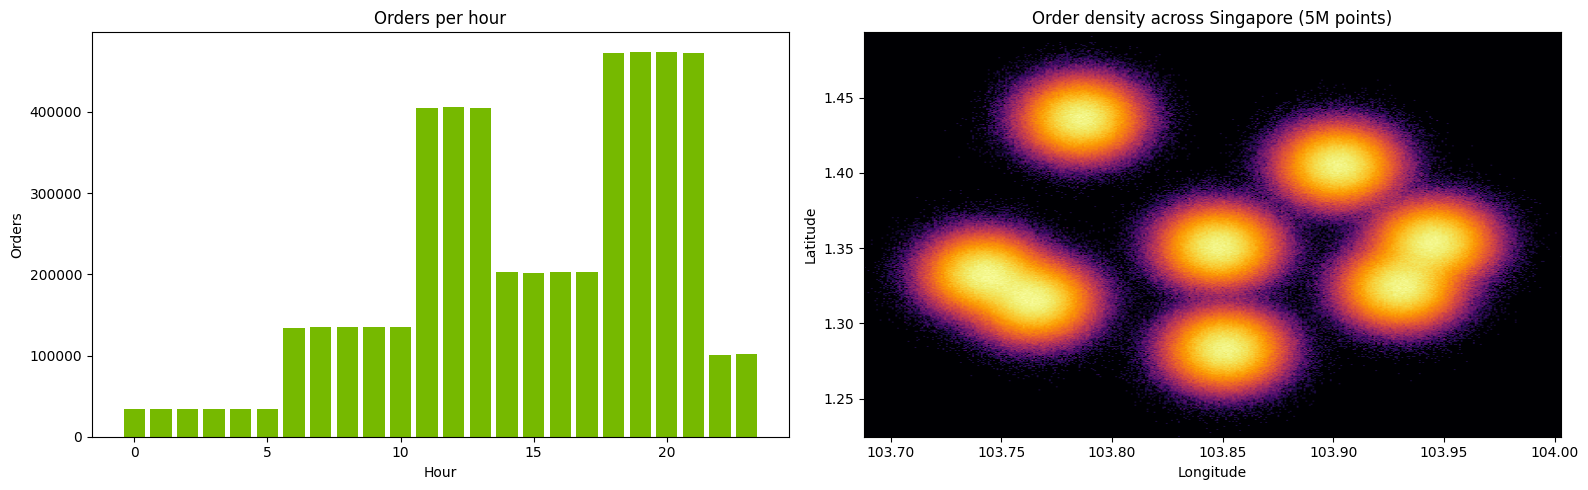

In [7]:
hourly = gdf.groupby("hour")["order_id"].count().sort_index().to_pandas()
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(hourly.index, hourly.values, color="#76b900")
ax[0].set_title("Orders per hour"); ax[0].set_xlabel("Hour"); ax[0].set_ylabel("Orders")

# Density map: bin all 5M points on the GPU, then draw only the grid
H, xe, ye = cp.histogram2d(cp.asarray(gdf["long"]), cp.asarray(gdf["lat"]), bins=400)
ax[1].imshow(cp.log1p(H).T.get(), origin="lower", extent=[float(xe[0]), float(xe[-1]), float(ye[0]), float(ye[-1])], cmap="inferno", aspect="auto")
ax[1].set_title("Order density across Singapore (5M points)"); ax[1].set_xlabel("Longitude"); ax[1].set_ylabel("Latitude")
plt.tight_layout(); plt.show()

## Part 6: ETL - save to Parquet
**Extract** (CSV) -> **Transform** (dtypes, new columns) -> **Load** (Parquet). Parquet is columnar and compressed, keeps dtypes, and lets me read only the columns I need.

In [10]:
out = gdf.drop(columns=["distance_band"])
out["town"] = out["town"].astype("str")   # GPU Parquet writer can't save category columns yet
out.to_parquet("orders.parquet")
!ls -lh orders.csv orders.parquet

timer("cuDF read CSV (2 columns)",     lambda: cudf.read_csv("orders.csv", usecols=["town", "late"]))
timer("cuDF read Parquet (2 columns)", lambda: cudf.read_parquet("orders.parquet", columns=["town", "late"]))

-rw-r--r-- 1 root root 356M Nov 20 07:47 orders.csv
-rw-r--r-- 1 root root  73M Nov 20 07:50 orders.parquet
cuDF read CSV (2 columns)             0.229 s
cuDF read Parquet (2 columns)         0.473 s


(              town  late
 0              CBD     0
 1         Clementi     0
 2          Punggol     0
 3        Woodlands     0
 4        Woodlands     0
 ...            ...   ...
 4999995   Tampines     1
 4999996   Tampines     0
 4999997  Woodlands     0
 4999998     Jurong     0
 4999999     Bishan     0
 
 [5000000 rows x 2 columns],
 0.4727437496185303)

-rw-r--r-- 1 root root 356M Nov 20 07:47 orders.csv
-rw-r--r-- 1 root root  73M Nov 20 07:50 orders.parquet
cuDF read CSV (2 columns)             0.252 s
cuDF read Parquet (2 columns)         0.054 s


(              town  late
 0              CBD     0
 1         Clementi     0
 2          Punggol     0
 3        Woodlands     0
 4        Woodlands     0
 ...            ...   ...
 4999995   Tampines     1
 4999996   Tampines     0
 4999997  Woodlands     0
 4999998     Jurong     0
 4999999     Bishan     0
 
 [5000000 rows x 2 columns],
 0.05400681495666504)

## Part 7: CuPy - convert lat/long to kilometres
Lat/long are angles, so distances in degrees are distorted. I convert to an x/y grid in km on the GPU (same idea as the course's OSGB36 `northing`/`easting`). Swapping `np` for `cp` is all it takes.

In [11]:
def latlong_to_km(lat, long, lat0=1.35, long0=103.82):
    x = (long - long0) * 111.32 * cp.cos(cp.radians(lat))   # east-west km
    y = (lat - lat0) * 110.57                               # north-south km
    return x, y

x, y = latlong_to_km(cp.asarray(gdf["lat"]), cp.asarray(gdf["long"]))
gdf["x_km"] = x.astype("float32")
gdf["y_km"] = y.astype("float32")
gdf[["lat", "long", "x_km", "y_km"]].head()

,lat,long,x_km,y_km
0,1.287836,103.867592,5.296621,-6.873494
1,1.310123,103.773514,-5.173458,-4.409167
2,1.426248,103.896507,8.514184,8.430695
3,1.446806,103.758003,-6.899246,10.703818
4,1.425398,103.784416,-3.959929,8.336727


## Part 8: K-Means - where to put 6 cloud kitchens
Unsupervised: K-Means finds 6 centres so every customer is as close as possible to one.

cuML KMeans on 5M points              2.003 s
    x_km  y_km
0   3.11  0.11
1  13.08 -1.24
2  -7.40 -2.87
3  -3.78  9.51
4   9.16  6.06
5   3.45 -7.41


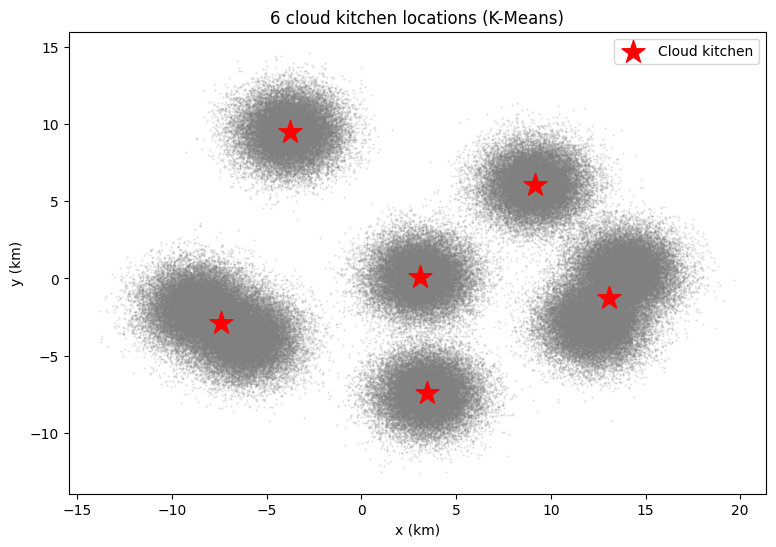

In [12]:
km = cuml.KMeans(n_clusters=6, random_state=42)
_, t = timer("cuML KMeans on 5M points", lambda: km.fit(gdf[["x_km", "y_km"]]))
kitchens = km.cluster_centers_
kitchens = kitchens.to_pandas() if hasattr(kitchens, "to_pandas") else pd.DataFrame(cp.asnumpy(cp.asarray(kitchens)))
kitchens.columns = ["x_km", "y_km"]
print(kitchens.round(2))

sample = gdf.sample(200_000, random_state=1).to_pandas()
plt.figure(figsize=(9, 6))
plt.scatter(sample["x_km"], sample["y_km"], s=0.2, alpha=0.3, c="grey")
plt.scatter(kitchens["x_km"], kitchens["y_km"], s=300, c="red", marker="*", label="Cloud kitchen")
plt.legend(); plt.title("6 cloud kitchen locations (K-Means)"); plt.xlabel("x (km)"); plt.ylabel("y (km)"); plt.show()

## Part 9: DBSCAN - hotspots of late rainy orders
DBSCAN doesn't need the number of clusters. A hotspot = at least `min_samples` late orders, each within `eps` km of another. Points that fit nowhere are noise (label -1).

In [13]:
late_rain = gdf.loc[(gdf["late"] == 1) & (gdf["is_raining"] == 1), ["x_km", "y_km"]].reset_index(drop=True)
late_rain = late_rain.sample(min(150_000, len(late_rain)), random_state=0).reset_index(drop=True)

db = cuml.DBSCAN(eps=0.25, min_samples=150)
late_rain["cluster"] = db.fit_predict(late_rain[["x_km", "y_km"]])

sizes = late_rain.loc[late_rain["cluster"] != -1, "cluster"].value_counts()
print("Hotspots found:", len(sizes), "| noise points:", int((late_rain["cluster"] == -1).sum()))
centroids = late_rain.loc[late_rain["cluster"] != -1].groupby("cluster")[["x_km", "y_km"]].mean().to_pandas()
print("Biggest hotspot centre (km):", centroids.loc[int(sizes.index[0])].round(2).to_dict())

[2026-11-20 07:50:31.315] [CUML] [info] Batch size limited by the chosen integer type (4 bytes). 16676 -> 14316. Using the larger integer type might result in better performance
Hotspots found: 6 | noise points: 43220
Biggest hotspot centre (km): {'x_km': -7.39, 'y_km': -2.87}


## Part 10: KNN - nearest kitchen for every order
Fit on the 6 kitchens, then ask "which kitchen is closest?" for all 5 million orders at once.

In [14]:
knn = cuml.NearestNeighbors(n_neighbors=1)
knn.fit(cudf.from_pandas(kitchens))
(dist, idx), t = timer("KNN for 5M orders", lambda: knn.kneighbors(gdf[["x_km", "y_km"]]))

to_cp = lambda a: a.values if hasattr(a, "values") else cp.asarray(a)   # cuDF or CuPy -> CuPy array
gdf["nearest_kitchen"] = to_cp(idx).ravel().astype("int8")
gdf["km_to_kitchen"] = to_cp(dist).ravel().astype("float32")
print(gdf.groupby("nearest_kitchen").agg({"order_id": "count", "km_to_kitchen": "mean"}).rename(columns={"order_id": "orders"}))

KNN for 5M orders                     0.745 s
                  orders  km_to_kitchen
nearest_kitchen                        
1                1242122       2.379916
4                 631022       1.693757
0                 626190       1.667690
2                1249048       2.234116
5                 626027       1.669667
3                 625591       1.666601


## Part 11: XGBoost - predict late deliveries
Supervised: learn from past orders whether a new order will be late. Train/test split so I test on unseen data. Evaluate with **ROC AUC** (0.5 = guessing, 1.0 = perfect).

XGBoost train (100 trees)             2.668 s


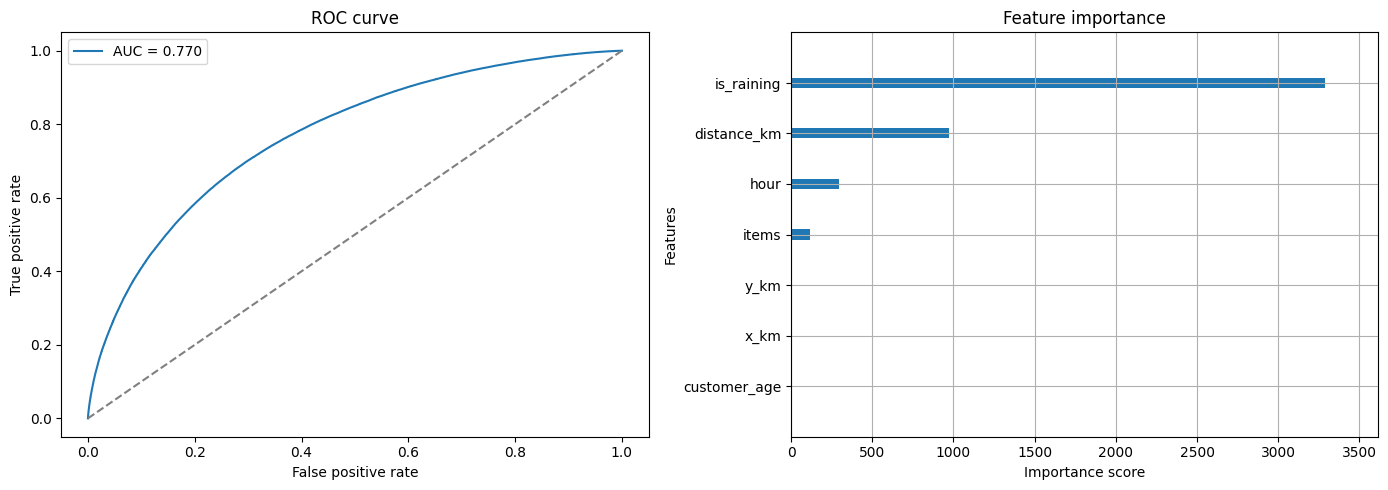

In [15]:
import xgboost as xgb
from cuml.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

features = ["hour", "is_raining", "items", "distance_km", "customer_age", "x_km", "y_km"]
X = gdf[features].astype("float32"); y = gdf["late"].astype("int32")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

params = {"device": "cuda", "tree_method": "hist", "objective": "binary:logistic",
          "eval_metric": "auc", "max_depth": 6, "learning_rate": 0.1}
dtrain = xgb.DMatrix(X_train, label=y_train)      # data goes straight from GPU DataFrame to XGBoost
dtest  = xgb.DMatrix(X_test,  label=y_test)
booster, t = timer("XGBoost train (100 trees)", lambda: xgb.train(params, dtrain, num_boost_round=100))

preds = booster.predict(dtest)
y_true = y_test.to_numpy()
auc = roc_auc_score(y_true, preds)
fpr, tpr, _ = roc_curve(y_true, preds)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); ax[0].plot([0, 1], [0, 1], "--", c="grey")
ax[0].set_title("ROC curve"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
xgb.plot_importance(booster, ax=ax[1], importance_type="gain", show_values=False)
ax[1].set_title("Feature importance"); plt.tight_layout(); plt.show()

**Expected:** distance, rain and hour should be the most important features, matching how the data was generated. Customer age should matter little, which is a good sanity check.

## Part 12: cuGraph - fastest route between towns
A small road graph: nodes = towns, edges = roads, weight = drive minutes. **SSSP** finds the quickest time from one town to every other. **PageRank** shows which town is the most connected "hub".

In [16]:
roads = pd.DataFrame({
    "src": ["CBD", "CBD", "CBD", "Bishan", "Bishan", "Bishan", "Jurong", "Clementi", "Tampines", "Punggol", "Woodlands", "Bedok"],
    "dst": ["Bishan", "Clementi", "Bedok", "Woodlands", "Punggol", "Clementi", "Clementi", "Woodlands", "Bedok", "Tampines", "Punggol", "Bishan"],
    "minutes": [15, 18, 17, 20, 18, 22, 10, 25, 10, 15, 28, 21],
})

if HAS_CUGRAPH:   # GPU graph analytics
    G = cugraph.Graph()                       # undirected = two-way roads
    G.from_cudf_edgelist(cudf.from_pandas(roads), source="src", destination="dst", edge_attr="minutes")
    print("Engine: cuGraph (GPU) | Nodes:", G.number_of_vertices())
    print("\nQuickest drive from Jurong (minutes):")
    print(cugraph.sssp(G, "Jurong").sort_values("distance")[["vertex", "distance"]])
    print("\nMost connected towns (PageRank):")
    print(cugraph.pagerank(G).sort_values("pagerank", ascending=False))
else:             # same algorithms with NetworkX on the CPU
    import networkx as nx
    G = nx.from_pandas_edgelist(roads, source="src", target="dst", edge_attr="minutes")
    print("Engine: NetworkX (CPU) | Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())
    print("\nQuickest drive from Jurong (minutes):")
    print(pd.Series(nx.single_source_dijkstra_path_length(G, "Jurong", weight="minutes")).sort_values())
    print("\nMost connected towns (PageRank):")
    print(pd.Series(nx.pagerank(G)).sort_values(ascending=False).round(3))

Engine: NetworkX (CPU) | Nodes: 8 | Edges: 12

Quickest drive from Jurong (minutes):
Jurong        0
Clementi     10
CBD          28
Bishan       32
Woodlands    35
Bedok        45
Punggol      50
Tampines     55
dtype: int64

Most connected towns (PageRank):
Bishan       0.194
Clementi     0.168
Bedok        0.125
Punggol      0.125
CBD          0.123
Woodlands    0.123
Tampines     0.089
Jurong       0.054
dtype: float64


## Findings (fill in after running, all based on mock data)
- GPU speed-up: read **__x**, groupby **__x** faster than pandas.
- Memory reduced by **__%** using smaller dtypes and category.
- Highest late rate: town **____** at **__%**; rain raises late rate from **__%** to **__%**.
- 6 cloud kitchens placed at the K-Means centres; average distance to nearest kitchen **__ km**.
- XGBoost predicts late orders with AUC **__**; top features: **____**.

## Reflection questions
1. Why is cuDF faster than pandas for 5 million rows, but maybe not for 500 rows?
2. Why did I convert lat/long to km before K-Means, DBSCAN and KNN?
3. When would I choose DBSCAN instead of K-Means?
4. Why can't I just use `predict()` with a 50% cutoff if late orders were very rare?
5. How would I scale this to 500 million orders across 4 GPUs? (Hint: Dask-cuDF, `.persist()`, `cuml.dask`.)